# TASK
The dataset textreview.csv consists of 2000 text reviews concerning products of more than one distinct industry branches.
Use a chosen method of clustering to find and name these main industry branches.


In [15]:
import pandas as pd 
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer



In [16]:
#Load Data 
df = pd.read_csv('textreviews.csv', encoding='cp1252')

In [17]:
df.head()

,id,text
0,1,Warn and super soft. love it !
1,2,"Love the high waist, prewashed softness, and r..."
2,3,"Nice jeans, but had to return. too tight in hi..."
3,4,"Im 5'1"" and about 110lbs. ordered the small be..."
4,5,NaN


In [18]:
#Count NaNs
df.isnull().sum()

id       0
text    26
dtype: int64

In [19]:
#Drop NaNs
df.dropna(inplace=True)

In [20]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english')) 

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mateo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [21]:
#Normalize the text data: lower case, sw, punctuation, numbers, whitespaces, etc.
def clean(text):
    #Lowercase
    text = text.lower()
    #Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)
    #Remove numbers
    text = re.sub(r'\d+', '', text)
    #Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    #remove english stopwords
    tokens = text.split()                                   # tokenizar
    tokens = [w for w in tokens if w not in stop_words]     # filtrar

    return ' '.join(tokens)
     
df['clean'] = df['text'].apply(clean)


In [ ]:
tfidf_vectorizer = TfidfVectorizer(min_df=5, max_df=0.5)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['clean'])

I will use KMeans because im familiarized with this method and it works for vectors (viewed as dots)

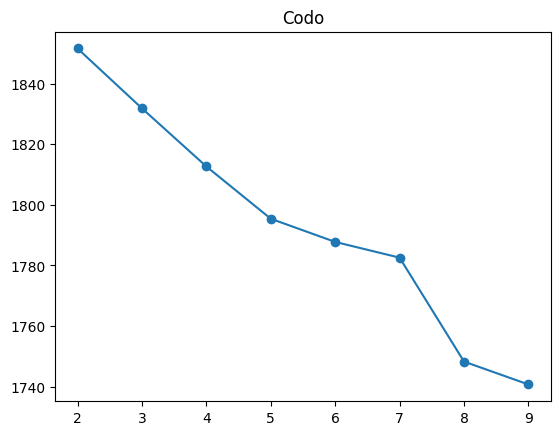

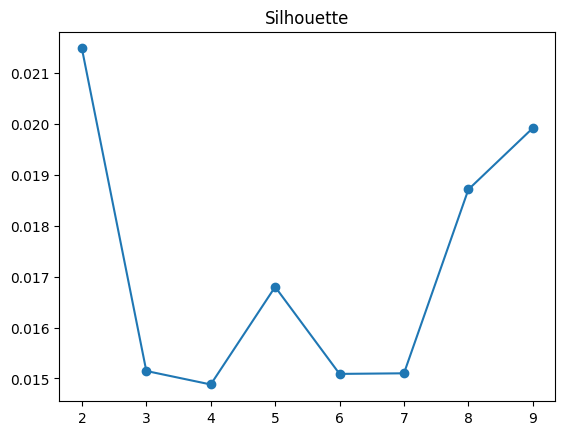

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inercias = []
sils = []

for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(tfidf_matrix)
    inercias.append(km.inertia_)
    sils.append(silhouette_score(tfidf_matrix, km.labels_))

plt.plot(range(2, 10), inercias, 'o-')
plt.title('Codo'); plt.show()

plt.plot(range(2, 10), sils, 'o-')
plt.title('Silhouette'); plt.show()


Based in both graphs, the best option is to pick k=2, I'll proceed with it:


In [30]:
km = KMeans(n_clusters=2, random_state=42)
km.fit(tfidf_matrix)
df['cluster'] = km.labels_

words = tfidf_vectorizer.get_feature_names_out()

for i in range(2):
    top = km.cluster_centers_[i].argsort()[-15:]   
    print('Cluster', i, words[top])


Cluster 0 ['small' 'really' 'fabric' 'perfect' 'would' 'wear' 'color' 'im' 'great'
 'fit' 'like' 'size' 'top' 'dress' 'love']
Cluster 1 ['ever' 'get' 'cool' 'really' 'playing' 'time' 'best' 'play' 'love'
 'awesome' 'addictive' 'good' 'great' 'fun' 'game']


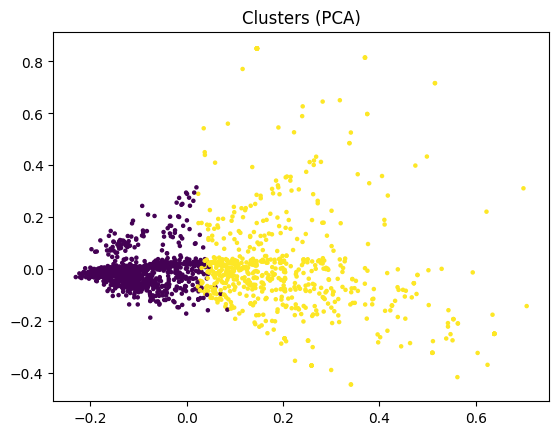

In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
puntos = pca.fit_transform(tfidf_matrix.toarray())

plt.scatter(puntos[:, 0], puntos[:, 1], c=df['cluster'], s=5)
plt.title('Clusters (PCA)')
plt.show()


## Conclusions

Using TF-IDF vectorization and K-Means, the reviews split into **two industry branches**:

- **Cluster 0 – Clothing / Fashion:** dress, top, size, fit, fabric, color, wear, small.
- **Cluster 1 – Video games / Mobile apps:** game, fun, play, playing, addictive, awesome, cool.

The choice of k=2 was supported by both the elbow method (largest inertia drop from k=1 to k=2) and the silhouette score (highest at k=2). Higher values of k did not reveal new branches; they only split the existing groups.

Silhouette scores were low overall (~0.02), which is common for TF-IDF on short texts, so the clusters overlap in vector space (as seen in the PCA plot). Even so, the top terms of each cluster are clearly distinct, and words like *love* and *great* appear in both because they express general sentiment rather than an industry.
